In [ ]:

from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="reczoo/MIND_small_x1",
    filename="MIND_small_x1.zip",
    repo_type="dataset",
    local_dir="data"
)

print("Downloaded successfully:", zip_path)


MIND_small_x1.zip: reconstructing file:   0%|          |  0.00B /  258MB            

MIND_small_x1.zip: downloading bytes:           |  0.00B            

Downloaded successfully: /content/data/MIND_small_x1.zip


In [ ]:

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()
    print("Total files:", len(files))
    for name in files[:30]:
        print(name)


Total files: 4
entity_emb_dim100.h5
news_corpus.tsv
train.csv
valid.csv


In [ ]:

import zipfile
import os

extract_path = "data/MIND_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction completed!")

print("Extracted files:")
print(os.listdir(extract_path))


Extraction completed!
Extracted files:
['valid.csv', 'news_corpus.tsv', 'train.csv', 'entity_emb_dim100.h5']


In [ ]:

import pandas as pd

news_path = "data/MIND_extracted/news_corpus.tsv"

df = pd.read_csv(
    news_path,
    sep="\t",
    low_memory=False
)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (65238, 7)

Column names:
['news_id', 'cat', 'sub_cat', 'title_entities', 'abstract_entities', 'title', 'abstract']

First 5 rows:


,news_id,cat,sub_cat,title_entities,abstract_entities,title,abstract
0,N55528,lifestyle,lifestyleroyals,Q80976^Q43274^Q9682,NaN,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the..."
1,N19639,health,weightloss,Q193583,Q193583,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...
2,N61837,news,newsworld,NaN,Q212,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...
3,N53526,health,voices,NaN,Q155223,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi..."
4,N38324,health,medical,Q3179593,Q3179593^Q171171^Q371820,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re..."


In [ ]:

# Check missing values in every column

print("Missing values per column:")
print(df.isnull().sum())

print("\nMissing percentage per column:")
print((df.isnull().sum() / len(df) * 100).round(2))


Missing values per column:
news_id                  0
cat                      0
sub_cat                  0
title_entities       17499
abstract_entities    17317
title                    0
abstract              3415
dtype: int64

Missing percentage per column:
news_id               0.00
cat                   0.00
sub_cat               0.00
title_entities       26.82
abstract_entities    26.54
title                 0.00
abstract              5.23
dtype: float64


In [ ]:

print("Duplicate news IDs:")
print(df["news_id"].duplicated().sum())

print("\nDuplicate titles:")
print(df["title"].duplicated().sum())

print("\nCompletely duplicate rows:")
print(df.duplicated().sum())



Duplicate news IDs:
0

Duplicate titles:
1313

Completely duplicate rows:
0


Number of categories: 18

Articles per category:
cat
news             20039
sports           19368
finance           3786
foodanddrink      3123
travel            3013
lifestyle         2991
video             2712
weather           2601
health            2207
autos             2076
tv                1027
music              902
entertainment      695
movies             672
kids                22
middleeast           2
northamerica         1
games                1
Name: count, dtype: int64


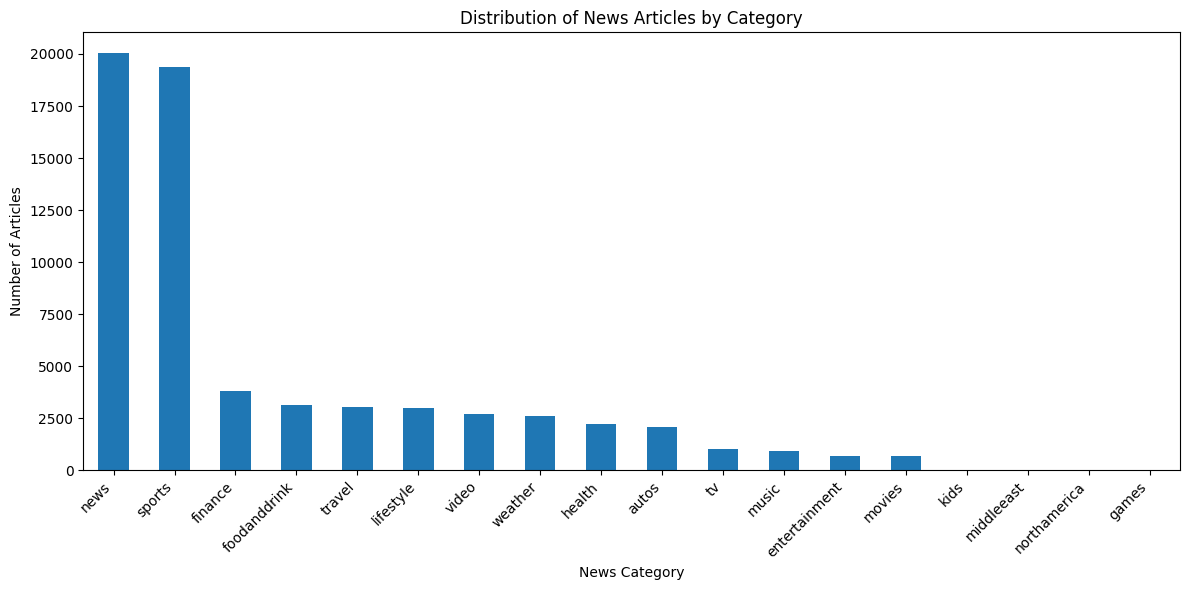

In [ ]:

import matplotlib.pyplot as plt

category_counts = df["cat"].value_counts()

print("Number of categories:", df["cat"].nunique())
print("\nArticles per category:")
print(category_counts)

plt.figure(figsize=(12, 6))

category_counts.plot(kind="bar")

plt.title("Distribution of News Articles by Category")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# Count words in titles and abstracts

df["title_length"] = df["title"].fillna("").str.split().str.len()

df["abstract_length"] = df["abstract"].fillna("").str.split().str.len()

print("Title length statistics:")
print(df["title_length"].describe())

print("\nAbstract length statistics:")
print(df["abstract_length"].describe())


Title length statistics:
count    65238.000000
mean        10.737224
std          3.247047
min          1.000000
25%          9.000000
50%         10.000000
75%         13.000000
max         57.000000
Name: title_length, dtype: float64

Abstract length statistics:
count    65238.000000
mean        34.859484
std         26.626741
min          0.000000
25%         15.000000
50%         25.000000
75%         64.000000
max        474.000000
Name: abstract_length, dtype: float64


In [ ]:

# Create a copy so the original dataset remains unchanged

df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)


Original shape: (65238, 9)
Working copy shape: (65238, 9)


In [ ]:

# Replace missing abstracts with empty strings

df_clean["abstract"] = df_clean["abstract"].fillna("")

# Ensure titles and abstracts are strings
df_clean["title"] = df_clean["title"].astype(str)
df_clean["abstract"] = df_clean["abstract"].astype(str)

print("Missing titles:",
      df_clean["title"].isnull().sum())

print("Missing abstracts:",
      df_clean["abstract"].isnull().sum())


Missing titles: 0
Missing abstracts: 0


In [ ]:

import re
import html
import unicodedata

def clean_text(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df_clean["title"] = df_clean["title"].apply(clean_text)

df_clean["abstract"] = df_clean["abstract"].apply(clean_text)

print("Text cleaning completed!")


Text cleaning completed!


In [ ]:

df_clean["document_text"] = (
    df_clean["title"] + " " + df_clean["abstract"]
).str.strip()

print("Example processed documents:")

for i in range(3):
    print("\nNews ID:", df_clean.iloc[i]["news_id"])
    print("Document:", df_clean.iloc[i]["document_text"])


Example processed documents:

News ID: N55528
Document: The Brands Queen Elizabeth, Prince Charles, and Prince Philip Swear By Shop the notebooks, jackets, and more that the royals can't live without.

News ID: N19639
Document: 50 Worst Habits For Belly Fat These seemingly harmless habits are holding you back and keeping you from shedding that unwanted belly fat for good.

News ID: N61837
Document: The Cost of Trump's Aid Freeze in the Trenches of Ukraine's War Lt. Ivan Molchanets peeked over a parapet of sand bags at the front line of the war in Ukraine. Next to him was an empty helmet propped up to trick snipers, already perforated with multiple holes.


In [ ]:

print("Total documents:", len(df_clean))

print("Empty documents:",
      (df_clean["document_text"] == "").sum())

print("Duplicate news IDs:",
      df_clean["news_id"].duplicated().sum())

display(
    df_clean[
        ["news_id", "cat", "title", "abstract", "document_text"]
    ].head()
)


Total documents: 65238
Empty documents: 0
Duplicate news IDs: 0


,news_id,cat,title,abstract,document_text
0,N55528,lifestyle,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...","The Brands Queen Elizabeth, Prince Charles, an..."
1,N19639,health,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,50 Worst Habits For Belly Fat These seemingly ...
2,N61837,news,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,The Cost of Trump's Aid Freeze in the Trenches...
3,N53526,health,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",I Was An NBA Wife. Here's How It Affected My M...
4,N38324,health,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...","How to Get Rid of Skin Tags, According to a De..."


In [ ]:

import numpy as np
import pandas as pd

SAMPLE_SIZE = 10000
RANDOM_STATE = 42

# Category counts
counts = df_clean["cat"].value_counts().sort_index()

# Proportional allocations
ideal = counts / counts.sum() * SAMPLE_SIZE

# Start with floor allocations
allocations = np.floor(ideal).astype(int)

# Ensure every nonempty category gets at least one article
allocations = allocations.clip(lower=1)

# Distribute remaining slots using largest remainders
remaining = SAMPLE_SIZE - allocations.sum()

if remaining > 0:
    priority = (ideal - allocations).sort_values(
        ascending=False
    )
    for category in priority.index[:remaining]:
        allocations[category] += 1

elif remaining < 0:
    priority = (ideal - allocations).sort_values()
    for category in priority.index:
        if remaining == 0:
            break
        if allocations[category] > 1:
            allocations[category] -= 1
            remaining += 1

# Sample within each category
sampled_parts = []

for category, n in allocations.items():
    group = df_clean[df_clean["cat"] == category]
    sampled_parts.append(
        group.sample(n=n, random_state=RANDOM_STATE)
    )

df_sample = pd.concat(
    sampled_parts,
    ignore_index=True
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Original dataset:", len(df_clean))
print("Sampled dataset:", len(df_sample))
print("Categories retained:", df_sample["cat"].nunique())


Original dataset: 65238
Sampled dataset: 10000
Categories retained: 18


In [ ]:

comparison = pd.DataFrame({
    "Original Count": df_clean["cat"].value_counts(),
    "Sample Count": df_sample["cat"].value_counts()
}).fillna(0)

comparison["Original %"] = (
    comparison["Original Count"] / len(df_clean) * 100
).round(2)

comparison["Sample %"] = (
    comparison["Sample Count"] / len(df_sample) * 100
).round(2)

comparison["Difference"] = (
    comparison["Sample %"] - comparison["Original %"]
).round(2)

display(comparison.sort_values(
    "Original Count", ascending=False
))


,Original Count,Sample Count,Original %,Sample %,Difference
cat,,,,,
news,20039,3071,30.72,30.71,-0.01
sports,19368,2969,29.69,29.69,0.00
finance,3786,580,5.80,5.80,0.00
foodanddrink,3123,479,4.79,4.79,0.00
travel,3013,462,4.62,4.62,0.00
lifestyle,2991,458,4.58,4.58,0.00
video,2712,416,4.16,4.16,0.00
weather,2601,399,3.99,3.99,0.00
health,2207,338,3.38,3.38,0.00


In [ ]:

import os

os.makedirs("data/processed", exist_ok=True)

output_path = "data/processed/mind_10k_clean.csv"

df_sample.to_csv(output_path, index=False)

print("Saved dataset to:", output_path)
print("Final shape:", df_sample.shape)


Saved dataset to: data/processed/mind_10k_clean.csv
Final shape: (10000, 10)


In [ ]:

# Create the final shared corpus

corpus = df_sample[
    [
        "news_id",
        "cat",
        "sub_cat",
        "title",
        "abstract",
        "document_text"
    ]
].copy()

# Rename category columns for clarity
corpus = corpus.rename(columns={
    "cat": "category",
    "sub_cat": "subcategory"
})

print("Final corpus shape:", corpus.shape)

display(corpus.head())


Final corpus shape: (10000, 6)


,news_id,category,subcategory,title,abstract,document_text
0,N1425,sports,football_ncaa,Report: Florida State considering firing Willi...,Willie Taggart should definitely look over his...,Report: Florida State considering firing Willi...
1,N39058,news,newsus,Meet the Marine the world just learned helped ...,Harold Keller never talked about his war exper...,Meet the Marine the world just learned helped ...
2,N55185,health,medical,SSM Health Medical Minute New Step Down Unit O...,SSM Health St. Joseph Hospital in Lake St. Lou...,SSM Health Medical Minute New Step Down Unit O...
3,N48277,news,newsworld,There's a sailboat frozen in the St. Croix River,The owner of a sailboat frozen in the St. Croi...,There's a sailboat frozen in the St. Croix Riv...
4,N38256,news,newsus,Kentucky man dies trying to save sons from Flo...,Stephone Ritchie Sr. was on a family vacation ...,Kentucky man dies trying to save sons from Flo...


In [ ]:

assert len(corpus) == 10000, "Incorrect corpus size!"

assert corpus["news_id"].is_unique, "Duplicate IDs found!"

assert corpus["document_text"].notna().all(), \
    "Missing document text found!"

assert corpus["document_text"].str.strip().ne("").all(), \
    "Empty documents found!"

assert corpus["category"].nunique() == 18, \
    "Some categories are missing!"

print("All validation checks passed!")


All validation checks passed!


In [ ]:

import os

os.makedirs("data/processed", exist_ok=True)

corpus_path = "data/processed/final_news_corpus.csv"

corpus.to_csv(corpus_path, index=False)

print("Final corpus saved:", corpus_path)
print("Shape:", corpus.shape)


Final corpus saved: data/processed/final_news_corpus.csv
Shape: (10000, 6)


In [ ]:

from google.colab import files

files.download("data/processed/final_news_corpus.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>